# Task 4 · Reconstruct the Flight (20 marks)

Connect your trackers to the provided pipeline and recover the lander's
velocity and 3D trajectory, then find out how the quality of your optical flow
decides the result. You write only the four short functions of Task 4.1; the
camera-motion fit (`provided/task4/motion_model.py`), the flight code
(`provided/task4/trajectory.py`) and the plots are provided.

The camera points straight down at flat ground. As the lander moves, the
tracked ground features between two consecutive frames undergo a similarity:
they scale, rotate and translate,

$$
\mathbf{x}_{k+1} = s_k R(\theta_k)\,\mathbf{x}_k + \mathbf{t}_k,
\qquad s_k = \frac{Z_k}{Z_{k+1}}.
$$

The provided fit estimates $s_k$, $\theta_k$ and $\mathbf{t}_k$ by robust least
squares, and the flight code turns them into altitude, position, velocity and
the 3D trajectory, in metres and seconds. The world frame is fixed to frame
270: $X$ to the right, $Y$ toward its top (image $y$ points down), $Z$ the
altitude (up).

**How this notebook works**

* Write your code only in the cells whose first line starts with `# YOUR CODE`.
  Only those cells are graded, and they are read from the **saved** notebook.
  Add your own cells anywhere for experiments or notes: they are never graded.
  A helper function you want graded with your code goes in a `# YOUR CODE` cell
  (a new cell whose first line is `# YOUR CODE` works too).
* Run the `check(...)` cell after your code: it tests your functions and prints
  PASS or FAIL for each test.
* Answer each question in the cell right below it, in one or two sentences,
  replacing *TODO*.
* Save often (Ctrl+S). Before you submit, run everything from a clean start:
  restart the kernel and run all cells, or run `python run_notebooks.py`.

In [1]:
# PROVIDED: run this cell first (save task3.ipynb before)
%matplotlib inline
import numpy as np
from provided.notebook import check, use_my_functions
from provided.sift import sift_matches, track_with_sift
from provided.task4.compare_trackers import compare
from provided.task4.run import read_motion, reconstruct_flight

use_my_functions(3)               # your Task 1 to 3 functions, from the saved notebooks

your functions from task1.ipynb, task2.ipynb, task3.ipynb (the saved files): spatial_gradients, temporal_difference, structure_tensor, feature_score, select_features, lucas_kanade_update, one_step_flow, track_point, track_points


## 4.1 Connect your trackers to the pipeline (4 marks)

Fill in the three adapters `one_step`, `iterative` and `sift_guided`, which
call your Task 3 `track_points`, and `track_pair`, which selects points
(Task 1.3), runs one tracker and keeps the valid tracks. A tracker is a
function `(image0, image1, points) -> (tracked, valid)`.

In [2]:
# YOUR CODE: Task 4.1

# the settings every tracker uses (keep them for the reference numbers)
MAX_POINTS = 200
FEATURE_RADIUS = 3
MIN_DISTANCE = 10
TRACK_RADIUS = 7
ITERATIONS = 10

def one_step(image0, image1, points):
    """One Lucas-Kanade update per point (the Task 2 method)."""
    return track_points(image0, image1, points, TRACK_RADIUS, max_iterations=1)


def iterative(image0, image1, points):
    """Iterative Lucas-Kanade per point (Task 3)."""
    return track_points(image0, image1, points, TRACK_RADIUS, max_iterations=ITERATIONS)


def sift_guided(image0, image1, points):
    """Iterative Lucas-Kanade started from SIFT guesses (Task 3.3)."""
    matches = sift_matches(image0, image1)
    return track_with_sift(track_points, image0, image1, points, matches, TRACK_RADIUS,
                           max_iterations=ITERATIONS)


def track_pair(image0, image1, tracker):
    """Select points in image0 and track them into image1 with `tracker`.

    Returns (points0, points1), keeping only the valid tracks.
    """
    points = select_features(image0, MAX_POINTS, FEATURE_RADIUS, MIN_DISTANCE)
    tracked, valid = tracker(image0, image1, points)
    valid = np.asarray(valid, dtype=bool)
    return points[valid], np.asarray(tracked)[valid]

In [3]:
check("4.1")

trackers = {"one-step": one_step, "iterative": iterative, "sift-guided": sift_guided}

Task 4.1 checks
  PASS  one step tracks a small shift
  PASS  iterative tracks a larger shift
  PASS  sift guided beats one step on large motion
  PASS  track pair selects and tracks points
4 of 4 passed


**(a)** Why must `track_pair` drop the failed tracks before the motion fit?

A failed track's position is wherever the iteration stopped (window off the image or singular system), so it carries no information and acts as a gross outlier; the least-squares similarity is pulled by such outliers, and the robust fit can only reject a limited fraction of them.

## 4.2 Read the motion from the images (4 marks)

The provided cell tracks all 143 frame pairs with your SIFT-guided tracker
(a few minutes), fits the camera motion of every pair and plots the zoom,
rotation and shift.

tracking 143 pairs with the sift-guided tracker (a few minutes)
  the first pair took 5.6 s, so all 143 pairs take about 13 minutes. If your select_features loops over every pixel, the speed tip in its docstring makes it much faster.
  270 to 271: 178 tracks
  290 to 291: 166 tracks
  310 to 311: 171 tracks
  330 to 331: 193 tracks
  350 to 351: 155 tracks
  370 to 371: 178 tracks
  390 to 391: 171 tracks
  410 to 411: 152 tracks
  412 to 413: 135 tracks
  saved outputs/task4/motion.csv (143 pairs)
  saved outputs\task4\zoom.png


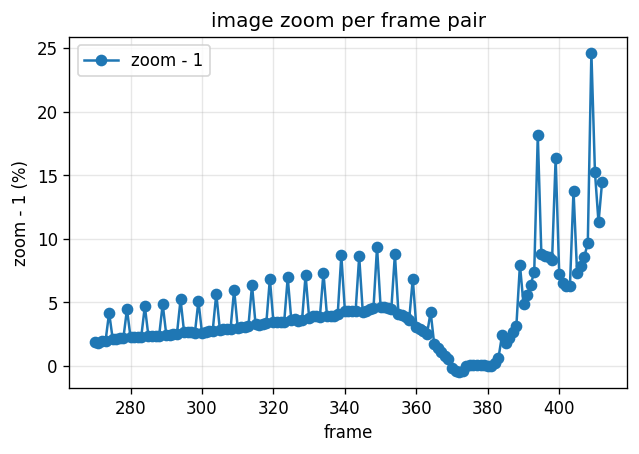

  saved outputs\task4\rotation.png


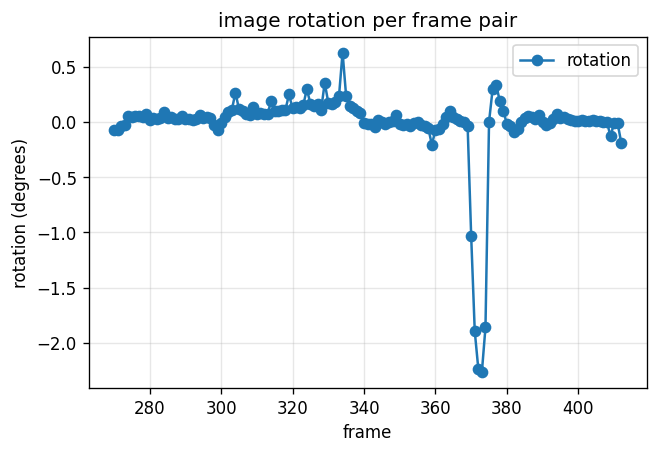

  saved outputs\task4\shift.png


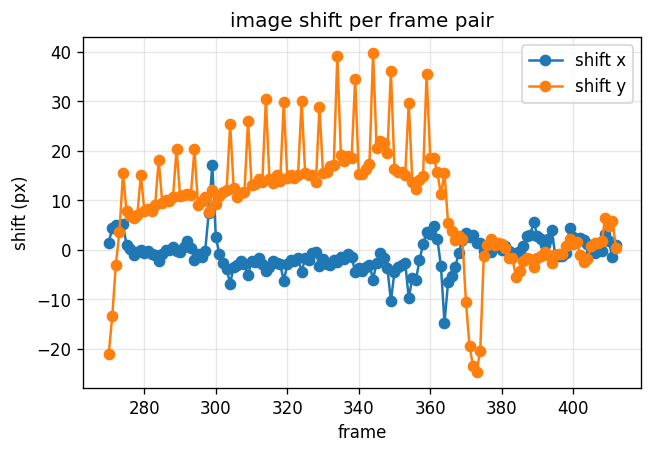

In [4]:
motion = read_motion(track_pair, trackers["sift-guided"])

**(a)** Why is the zoom $s_k = Z_k / Z_{k+1}$? Use the pinhole model.

Pinhole: a ground point at horizontal offset $X$ from the optical axis appears at $x = fX/Z$. For flat ground and a camera looking straight down, $X$ (in the camera frame) stays the same between frames, so $x_{k+1}/x_k = Z_k/Z_{k+1}$: every image distance is multiplied by $s_k = Z_k/Z_{k+1}$ (> 1 while descending).

**(b)** What are the phases of the descent, and at about which frames do they change?

≈270–272: end of the pitch-over (large transient shift). ≈272–350: approach, descending with forward drift (zoom rising from 2 % to 4.5 % per frame, shift y 8→20 px). ≈350–368: braking, zoom and shift fall to ≈ 0. ≈368–384: hover at about 100 m (zoom ≈ 0) with an obstacle-avoidance manoeuvre around 370–375 (≈ −2°/frame yaw and a sideways shift). ≈384–413: final slow vertical descent (shift ≈ 0, zoom rising to 10–25 %).

**(c)** Which pattern in these plots is not caused by the lander, and how can you tell?

The spikes every 5th pair (274, 279, …, 409) where zoom and shift jump to about twice their neighbours and drop back: these steps span 2 s instead of 1 s (camera timing / skipped image), not lander motion. A lander cannot double its speed for exactly one frame on a perfectly regular 5-frame period; `step_multiples` finds 25 such steps, which is why the duration is 168 s for 143 pairs.

## 4.3 Reconstruct the flight (4 marks)

The provided cell turns the motion into the altitude, the velocity
$(v_X, v_Y, v_Z)$, the time to touchdown $\tau = Z / (-v_Z)$, the 3D trajectory
and the ground track (seen from above, $X$ to the right and $Y$ up).

  saved outputs\task4\altitude.png


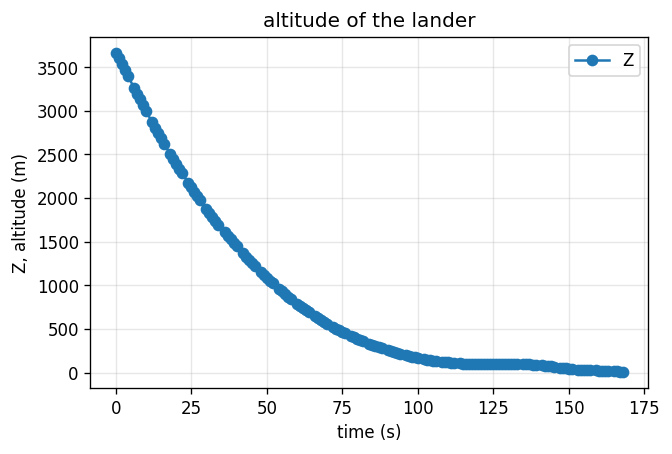

  saved outputs\task4\velocity.png


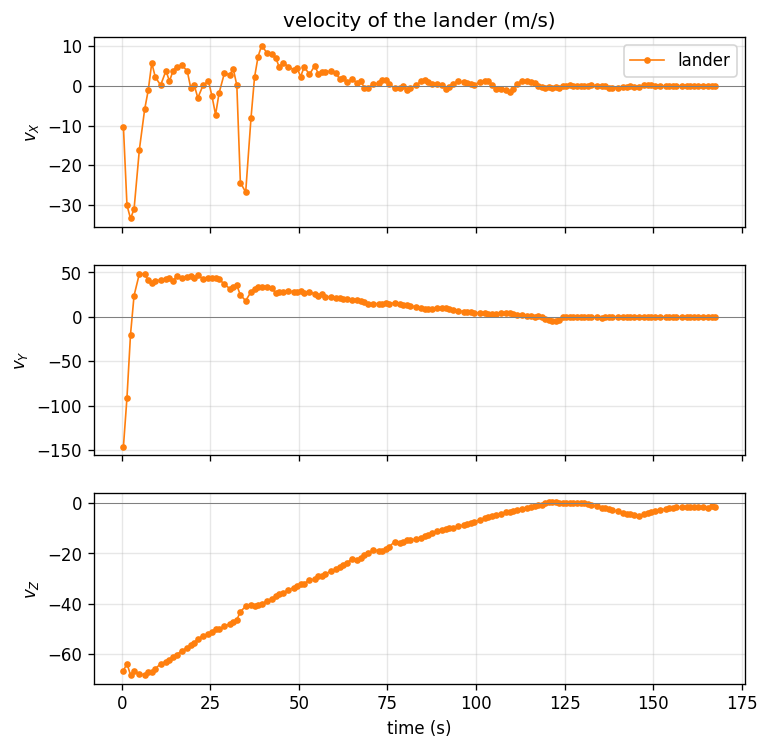

  saved outputs\task4\time_to_touchdown.png


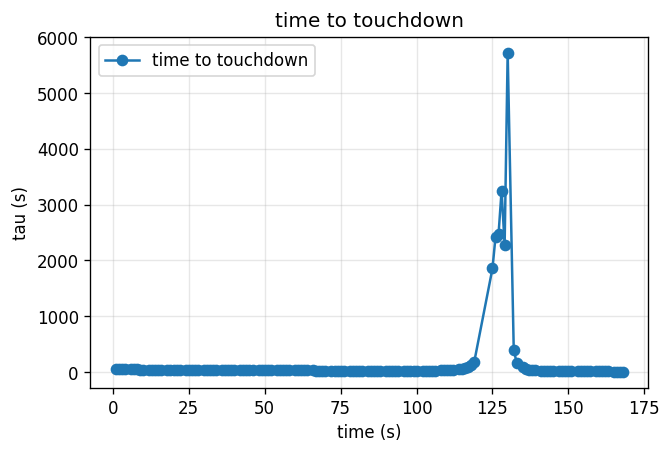

  saved outputs\task4\trajectory_3d.png


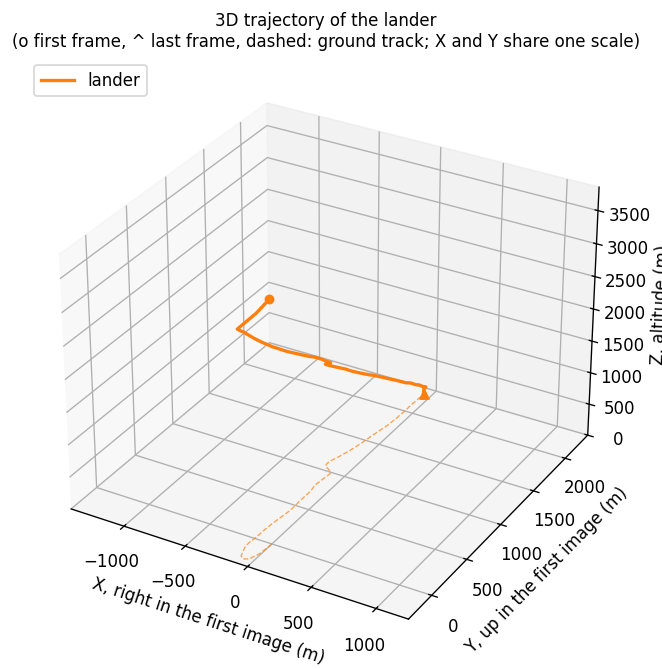

  saved outputs\task4\ground_track.png


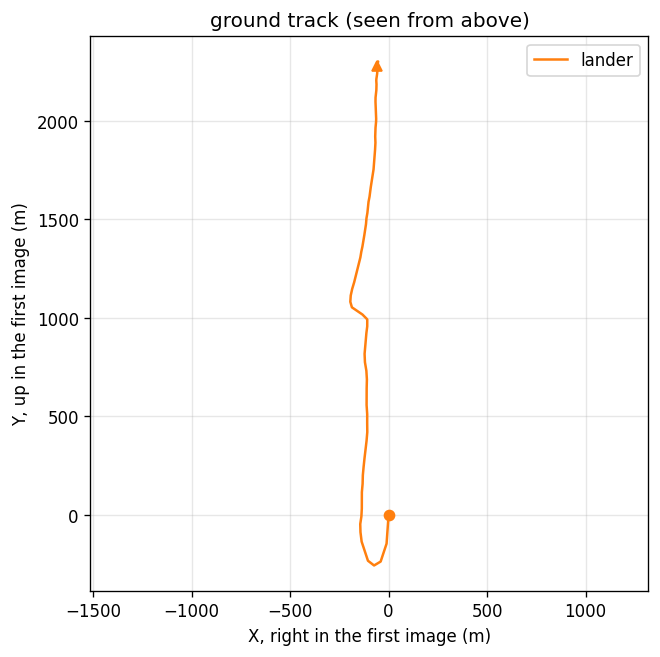

  saved outputs\task4\summary.json
  summary: frames [270, 413], length_unit m, time_unit s, start_Z 3667, end_Z 9.101, duration 168, horizontal_drift 2280, max_descent_speed 68.38


In [5]:
flight, summary = reconstruct_flight(motion)

**Table.** Fill in the numbers printed above (also in `outputs/task4/summary.json`).

| Quantity | Value |
|----------|-------|
| Start and end altitude Z | 3667 m → 9.1 m |
| Duration | 168 s |
| Largest descent speed | 68.4 m/s |
| Horizontal drift | 2280 m |

**(a)** Which result do you trust least, and why?

The start altitude (3667 m) and the horizontal motion at the very start: the altitude is extrapolated from the single 100 m reading at frame 381 through 111 multiplied zooms, so small zoom errors compound, and at frames 270–272 the camera is still finishing the pitch-over (not nadir), giving an implausible v_Y ≈ −145 m/s that also feeds the drift.

## 4.4 Compare the three trajectories (5 marks)

The provided cell runs the whole pipeline once per tracker on the same points
and draws the three ground tracks together (several minutes the first time;
the tracks are saved and reused while your code stays the same).

reusing the saved tracks (your code has not changed since they were made)
  saved outputs\task4\compare\ground_track.png


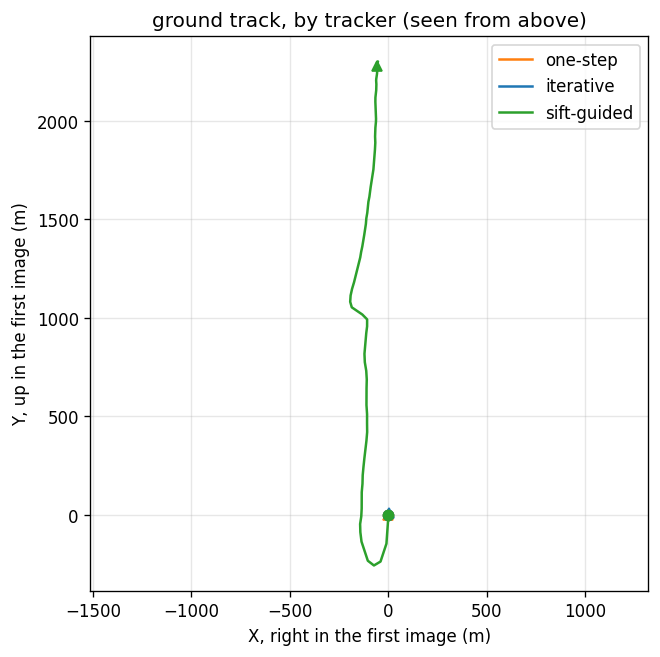

  saved outputs/task4/compare/summary.csv
      one-step: end Z 99 m, drift 1.299 m, median residual 0.23 px
     iterative: end Z 92.89 m, drift 8.796 m, median residual 1.78 px
   sift-guided: end Z 9.101 m, drift 2280 m, median residual 0.35 px


In [6]:
table = compare(trackers, track_pair)

**Table.** Fill in the numbers printed above (also in `outputs/task4/compare/summary.csv`).

| Tracker | End altitude | Horizontal drift | Median residual |
|---------|--------------|------------------|-----------------|
| one-step | 99.0 m | 1.30 m | 0.23 px |
| iterative | 92.9 m | 8.80 m | 1.78 px |
| SIFT-guided | 9.10 m | 2280 m | 0.35 px |

**(a)** Which trajectory do you trust, and which Task 3 result supports it?

SIFT-guided: it is the only one that reaches near the ground (9.1 m), while the others claim the lander barely descended from about 100 m. Task 3.4 supports it: on 300 to 301 SIFT-guided gives 10.03 px while iterative (2.38 px) and one-step (0.30 px) get stuck near zero, as the error sweep predicts for motions above ~2.4 px.

**(b)** Does a low median residual mean a tracker is right? Use your numbers.

No. One-step has the lowest median residual (0.23 px, vs 0.35 px for SIFT-guided) yet gives a wrong flight (end Z 99 m): when every track underestimates the motion, the tracks still agree with one another on a near-identity similarity. The residual measures consistency with the model, not correctness.

Optional, not graded: the next cell writes
`outputs/task4/trajectory_animation.html`, the three flights as an interactive
3D animation to open in a web browser.

In [7]:
from provided.task4.animate_trajectory import main as animate
animate([])

  saved C:\Users\Tanushka\Downloads\ES666_A3_Lunar_Landing\outputs\task4\trajectory_animation.html  (open it in a web browser)
done


## 4.5 Where does uncertainty come from? (3 marks)

**(a)** Why does a small error in each zoom grow along the descent?

Each altitude is the anchor times a product of zooms, $Z_k = Z_{anchor}\prod s^{-1}$, so log-altitude is a sum of per-step log-zoom errors: random errors grow like $\sqrt{n}$ and biases grow linearly in $n$ (e.g. 0.1 % bias over 111 steps ≈ 12 %). Horizontal steps scale with $Z$, so the error also spreads into position and drift.

**(b)** What changes if the anchor altitude is 10 % too high? And if the focal length is?

Anchor 10 % too high: all altitudes, horizontal displacements and velocities become 10 % too large (the relative shape and τ = Z/(−v_Z) do not change). Focal length 10 % too high: altitudes, v_Z and τ do not change (zoom does not depend on f), but horizontal displacements ∝ Z/f, so X, Y, drift and horizontal velocity become ≈ 9 % too small.

# Final Mission Report · What Did We Learn? (bonus, 5 marks)

One or two sentences each, with one piece of evidence from your results.

**Q1.** Where in the descent does "all pixels in a window move together" fail most, and what in your results shows it?

Near touchdown (≈ 405–413), where the zoom per step is 10–25 %: a window is stretched, not just shifted, and nearby relief and dust move differently. Evidence: the median residual jumps to 12–16 px at 411–412 (vs ≈ 0.2 px earlier) and 60 % of SIFT-guided tracks fail on 409 to 410.

**Q2.** Would a pyramidal (coarse-to-fine) KLT tracker fix 300 to 301? Would it fix 409 to 410? Why?

300 to 301 yes: ≈ 10 px of nearly pure translation becomes ≈ 1.3 px at 1/8 scale, inside the 2.4 px range where iterative LK converges. 409 to 410 probably not fully: displacements up to 61 px with 25 % zoom need many levels on a 588×432 image (little texture left), the window deformation is not a translation at any level, and points that leave the image are lost anyway.

**Q3.** If you ignored the pattern from Task 4.2, which Task 4.3 results would be wrong, and by how much?

The 25 two-second steps would be treated as 1 s: duration would be 143 s instead of 168 s, and those steps would show velocity spikes of about 2×, e.g. the largest descent speed 136 m/s instead of 68 m/s (τ too small there). Altitudes, positions and drift would not change, since they do not depend on time.

**Q4.** Where does the "flat ground, camera straight down" model fail, and what error does it cause?

At the start (270–272), while the lander is still finishing its pitch-over and the camera is tilted: tilt changes are read as image shift, giving a spurious v_Y ≈ −145 m/s and v_X ≈ −30 m/s. Near touchdown, crater relief is not small compared with ≈ 10 m altitude, so the zoom varies across the image and the residuals grow to 12–16 px.

**Q5.** Name one independent measurement that would check your trajectory, and what it would check.

The lander's laser/microwave altimeter (or the published radio-tracking trajectory) would check the altitude profile, i.e. the accumulated zooms, e.g. our 3667 m start; locating the landing site in orbital images would check the horizontal drift and ground track in metres.

# References

List every source you used, including the Chang'e-5 landing camera data (level 2A, https://moon.bao.ac.cn).

- Chang'e-5 landing camera (LCAM) level 2A images, 1 December 2020, Ground Research and Application System of China's Lunar and Planetary Exploration Program, https://moon.bao.ac.cn
- ES666 Assignment 3 handout (`ES666_A3_Handout.pdf`, `tasks.md`) and provided starter code
- B. D. Lucas and T. Kanade, "An Iterative Image Registration Technique with an Application to Stereo Vision", IJCAI 1981
- J. Shi and C. Tomasi, "Good Features to Track", CVPR 1994
- D. G. Lowe, "Distinctive Image Features from Scale-Invariant Keypoints", IJCV 2004
- Altitude anchor: descent trajectory reconstruction from radio tracking, Remote Sensing 13, 4837 (2021)